# Checkpoint 3 — Clustering e segmentação de clientes

**Disciplina: Modelagem Linear para Aprendizado de Máquina**  
**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome(s) e RM(s):**
* Gustavo Guedes Pereira — RM 569779
* Lucas Angelo — RM 569530
* Gustavo de Souza — RM 570746
* Arthur Tae — RM 570647
* Gabriel Rodrigues — RM 569322

**Turma:** 1CCPJ

## Situação-problema

Uma empresa de comércio eletrônico deseja conhecer os diferentes perfis de compra de seus clientes para planejar ações de relacionamento. Cada registro reúne o histórico de um cliente nos últimos 12 meses, calculado na mesma data de referência.

Seu desafio é identificar grupos de clientes com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 clientes fictícios**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de pessoas, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_cliente` | Identificador fictício do cliente | Identificação; excluir do modelo |
| `gasto_total_12_meses` | Soma dos valores das compras nos últimos 12 meses | R$ |
| `quantidade_compras_12_meses` | Número de compras realizadas nos últimos 12 meses | Compras |
| `dias_desde_ultima_compra` | Dias entre a compra mais recente e a data de referência | Dias |

O gasto descreve o valor acumulado; a quantidade informa a frequência de compras; o tempo desde a última compra representa a recência. Um valor menor de dias indica uma compra mais recente.

Clientes com gasto semelhante podem ter quantidades de compras e recências diferentes. Essas medidas não informam renda, satisfação ou o motivo de um cliente deixar de comprar.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [10]:
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)

In [11]:
DADOS_CSV = """
id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
CL001,2415.04,22,14
CL002,6136.88,7,87
CL003,8520.86,31,16
CL004,712.95,1,132
CL005,7964.46,6,104
CL006,897.35,5,99
CL007,606.06,6,108
CL008,8132.06,10,98
CL009,8992.43,30,9
CL010,8439.0,32,4
CL011,3086.0,21,14
CL012,3505.35,17,28
CL013,3824.73,17,18
CL014,14019.61,19,14
CL015,2114.77,23,21
CL016,1161.25,2,122
CL017,6691.19,7,78
CL018,7312.2,4,95
CL019,711.17,5,177
CL020,8414.07,26,0
CL021,7911.54,6,38
CL022,2076.62,22,12
CL023,8985.03,6,45
CL024,7249.79,5,99
CL025,5784.63,8,82
CL026,7510.04,24,14
CL027,996.41,2,147
CL028,3031.75,25,19
CL029,648.73,4,51
CL030,533.45,5,50
CL031,9298.68,6,74
CL032,7208.79,22,10
CL033,6105.18,6,84
CL034,2043.65,26,15
CL035,6791.38,7,50
CL036,554.34,3,95
CL037,8296.09,44,16
CL038,2567.37,16,12
CL039,9130.6,26,13
CL040,3430.01,30,19
CL041,8305.2,34,9
CL042,5551.75,7,58
CL043,7431.23,10,58
CL044,1006.79,6,57
CL045,6493.35,6,90
CL046,5545.24,11,92
CL047,3131.7,25,7
CL048,2725.2,24,11
CL049,1024.4,5,60
CL050,825.75,4,66
CL051,5015.92,4,80
CL052,2768.34,19,34
CL053,6684.99,7,54
CL054,3195.3,30,9
CL055,10387.5,30,12
CL056,876.94,6,54
CL057,624.05,5,104
CL058,956.59,3,167
CL059,12263.9,32,14
CL060,1183.14,2,109
CL061,6823.82,5,42
CL062,6533.72,6,80
CL063,11253.35,27,0
CL064,7448.21,23,8
CL065,1053.25,4,110
CL066,5618.55,19,10
CL067,2422.63,20,28
CL068,8860.03,31,9
CL069,11409.28,24,12
CL070,2554.03,26,16
CL071,648.36,2,64
CL072,1625.9,18,13
CL073,924.97,5,98
CL074,806.85,5,155
CL075,11288.98,24,12
CL076,5693.5,2,86
CL077,2157.1,25,10
CL078,6570.68,7,37
CL079,2288.58,20,13
CL080,420.04,5,89
CL081,7737.84,16,22
CL082,7535.89,5,25
CL083,8534.53,19,15
CL084,6270.62,7,137
CL085,5923.75,26,23
CL086,1154.26,6,122
CL087,4933.71,7,90
CL088,658.41,4,151
CL089,10109.2,20,7
CL090,9140.44,32,0
CL091,7116.95,7,103
CL092,2173.18,25,5
CL093,6307.09,7,67
CL094,4787.96,5,65
CL095,715.66,3,79
CL096,12276.45,23,8
CL097,7253.65,27,14
CL098,710.74,5,130
CL099,9069.7,4,65
CL100,3510.14,24,14
CL101,940.47,3,111
CL102,2393.85,30,21
CL103,5512.15,5,106
CL104,2574.35,23,6
CL105,8571.63,19,7
CL106,2021.96,22,8
CL107,3505.47,7,16
CL108,2254.15,25,18
CL109,701.64,4,38
CL110,2018.77,32,10
CL111,2920.7,21,18
CL112,1120.58,5,86
CL113,1339.64,3,108
CL114,3017.75,28,5
CL115,9374.86,29,12
CL116,485.39,4,132
CL117,6896.28,25,10
CL118,8717.02,42,10
CL119,10309.74,28,16
CL120,2676.42,17,12
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Clientes: {len(df)}")

id_cliente  gasto_total_12_meses  quantidade_compras_12_meses  dias_desde_ultima_compra
     CL001               2415.04                           22                        14
     CL002               6136.88                            7                        87
     CL003               8520.86                           31                        16
     CL004                712.95                            1                       132
     CL005               7964.46                            6                       104
Clientes: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o gasto total poderia esconder diferenças de comportamento?


In [12]:
cols = ['gasto_total_12_meses', 'quantidade_compras_12_meses', 'dias_desde_ultima_compra']
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print('Ids duplicados:', df['id_cliente'].duplicated().sum())
desc = df[cols].describe().T
desc['amplitude'] = desc['max'] - desc['min']
desc.round(2)

(120, 4)
id_cliente                      object
gasto_total_12_meses           float64
quantidade_compras_12_meses      int64
dias_desde_ultima_compra         int64
dtype: object
id_cliente                     0
gasto_total_12_meses           0
quantidade_compras_12_meses    0
dias_desde_ultima_compra       0
dtype: int64
Ids duplicados: 0


,count,mean,std,min,25%,50%,75%,max,amplitude
gasto_total_12_meses,120.0,4829.03,3465.47,420.04,1554.34,4306.34,7516.50,14019.61,13599.57
quantidade_compras_12_meses,120.0,14.97,10.81,1.00,5.00,10.50,24.25,44.00,43.00
dias_desde_ultima_compra,120.0,50.93,45.41,0.00,12.00,31.00,87.50,177.00,177.00


**Resposta e observações:**

- A base tem 120 clientes e 4 colunas, sem valores ausentes e sem ids repetidos.
- O gasto total tem a maior amplitude (de R$ 420,04 a R$ 14.019,61). Compras vão de 1 a 44 e dias desde a última compra de 0 a 177.
- Só o gasto esconderia diferenças: dois clientes com o mesmo gasto podem ter frequência e recência bem diferentes, e isso muda a ação da empresa.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_cliente` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [13]:
X = df[cols]
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)
print(X_padronizado.mean(axis=0).round(6))
print(X_padronizado.std(axis=0).round(6))
df.head(3)

[ 0. -0.  0.]
[1. 1. 1.]


,id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
0,CL001,2415.04,22,14
1,CL002,6136.88,7,87
2,CL003,8520.86,31,16


**Justificativa da padronização:**

O K-Means usa distância, e o gasto (em reais) tem valores muito maiores que compras e dias. Sem padronizar, o gasto dominaria os grupos. O StandardScaler deixa as três variáveis com média 0 e desvio 1, então todas pesam de forma parecida.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, gastos de R$ 100, R$ 120 e R$ 140 formam um grupo com centroide de R$ 120. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800$$

Esse 800 é uma medida de dispersão em reais ao quadrado; não é o total gasto pelos clientes.

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa dinheiro gasto. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


 k  inercia
 1   360.00
 2   164.71
 3   110.52
 4    60.65
 5    46.92
 6    40.08
 7    33.75
 8    28.41


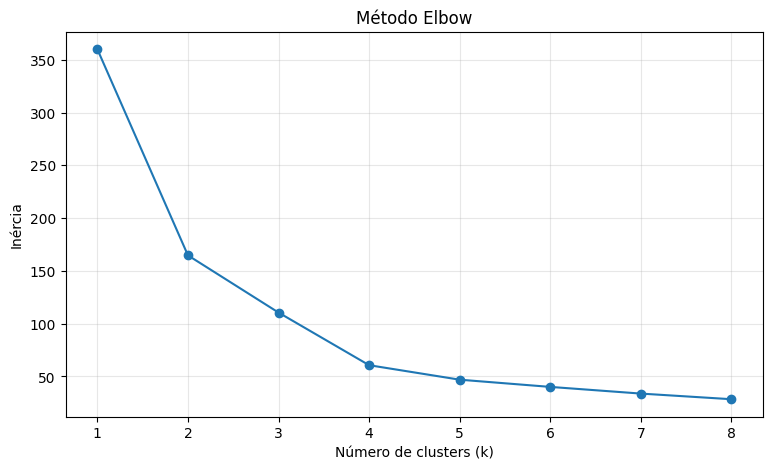

In [14]:
distorcoes = []
for k in range(1, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

print(pd.DataFrame({'k': range(1, 9), 'inercia': np.round(distorcoes, 2)}).to_string(index=False))

plt.plot(range(1, 9), distorcoes, marker='o')
plt.title('Método Elbow')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.grid(alpha=0.3)
plt.show()

**Leitura do Elbow:**

A inércia cai de 360,00 (k=1) para 164,71 (k=2), 110,52 (k=3) e 60,65 (k=4). De k=4 para k=5 cai só para 46,92 (queda de 13,73, contra 49,87 de k=3 para 4). O cotovelo está em **k=4**.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


 k  silhouette
 2      0.4842
 3      0.4889
 4      0.5526
 5      0.5433
 6      0.5037
 7      0.4644
 8      0.4771


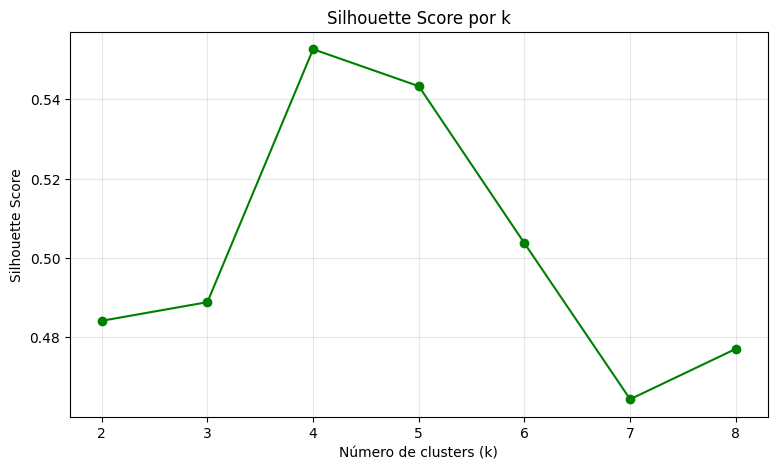

In [15]:
scores = []
for k in range(2, 9):
    rotulos = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_padronizado)
    scores.append(silhouette_score(X_padronizado, rotulos))

tabela_sil = pd.DataFrame({'k': range(2, 9), 'silhouette': np.round(scores, 4)})
print(tabela_sil.to_string(index=False))

plt.plot(range(2, 9), scores, marker='o', color='green')
plt.title('Silhouette Score por k')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.grid(alpha=0.3)
plt.show()

**Comparação das evidências:**

O maior Silhouette Score é de k=4 (0,5526), seguido de k=5 (0,5433) e k=6 (0,5037). O Elbow também aponta k=4, então os dois métodos concordam.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de clientes por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [16]:
k_escolhido = 4
modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)

df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais

print(df_resultados['cluster'].value_counts().sort_index())
print('Silhouette final:', round(silhouette_score(X_padronizado, rotulos_finais), 4))

cluster
0    28
1    30
2    32
3    30
Name: count, dtype: int64
Silhouette final: 0.5526


**k escolhido e justificativa:**

Escolhi **k = 4**: tem o maior Silhouette (0,5526), coincide com o cotovelo do Elbow e gera quatro grupos equilibrados (28, 30, 30 e 32 clientes) com perfis fáceis de interpretar.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Gasto total nos últimos 12 meses × quantidade de compras nos últimos 12 meses.
2. Gasto total nos últimos 12 meses × dias desde a última compra.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de clientes e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de relacionamento para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Gasto alto não comprova renda elevada nem satisfação. Muitos dias sem comprar não comprovam que o cliente abandonou a empresa. Uma ação de reativação, fidelização ou oferta direcionada deve ser apresentada como hipótese, com os dados adicionais necessários para avaliá-la.


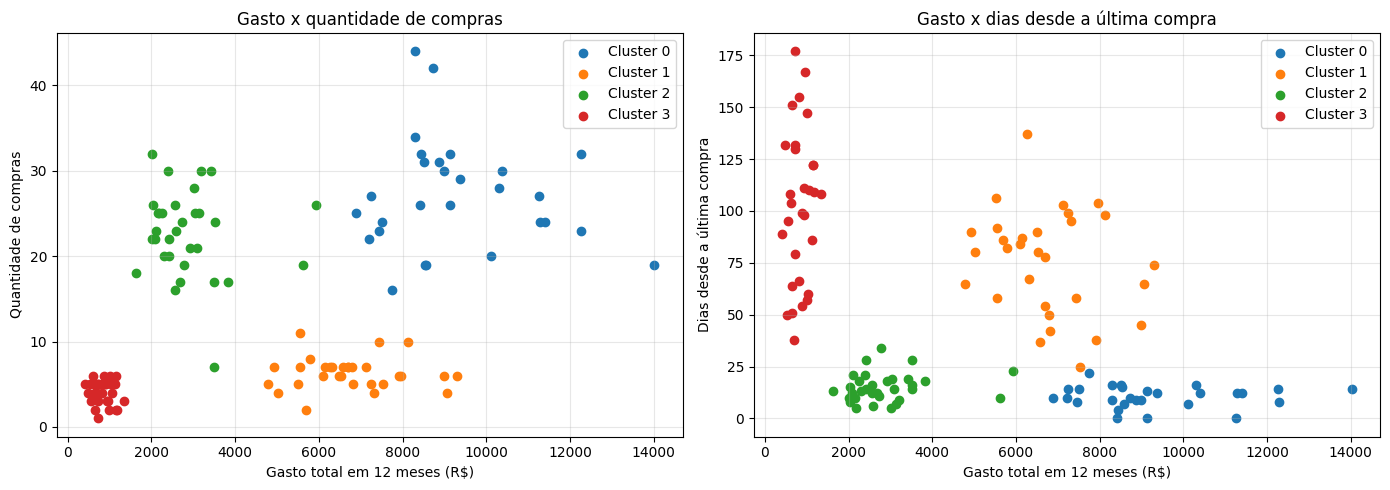

In [17]:
cores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for c in range(k_escolhido):
    sub = df_resultados[df_resultados['cluster'] == c]
    axes[0].scatter(sub['gasto_total_12_meses'], sub['quantidade_compras_12_meses'], color=cores[c], label=f'Cluster {c}')
    axes[1].scatter(sub['gasto_total_12_meses'], sub['dias_desde_ultima_compra'], color=cores[c], label=f'Cluster {c}')

axes[0].set_title('Gasto x quantidade de compras')
axes[0].set_xlabel('Gasto total em 12 meses (R$)')
axes[0].set_ylabel('Quantidade de compras')
axes[1].set_title('Gasto x dias desde a última compra')
axes[1].set_xlabel('Gasto total em 12 meses (R$)')
axes[1].set_ylabel('Dias desde a última compra')
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [18]:
perfil = df_resultados.groupby('cluster').agg(
    clientes=('id_cliente', 'count'),
    gasto_medio=('gasto_total_12_meses', 'mean'),
    compras_media=('quantidade_compras_12_meses', 'mean'),
    dias_media=('dias_desde_ultima_compra', 'mean'),
).round(1)
perfil

,clientes,gasto_medio,compras_media,dias_media
cluster,,,,
0,28,9309.6,27.1,10.5
1,30,6741.4,6.3,75.6
2,32,2861.7,22.7,15.0
3,30,833.3,4.1,102.4


**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| 0 | 28 clientes; gasto médio R$ 9.309,60; 27,1 compras; 10,5 dias. Alto valor, frequentes e recentes. | Fidelização: benefícios e acesso antecipado a lançamentos. | Margem, satisfação (NPS) e custo dos benefícios. |
| 1 | 30 clientes; gasto médio R$ 6.741,40; 6,3 compras; 75,6 dias. Alto valor, mas compram pouco e há mais tempo. | Reativação com oferta ou lembrete de recompra (hipótese). | Categorias compradas e motivo do intervalo entre compras. |
| 2 | 32 clientes; gasto médio R$ 2.861,70; 22,7 compras; 15,0 dias. Compram muito, com valor baixo por compra. | Aumentar o ticket com combos e frete grátis acima de um valor. | Itens por pedido e margem dos produtos. |
| 3 | 30 clientes; gasto médio R$ 833,30; 4,1 compras; 102,4 dias. Baixo valor e mais distantes. | Campanha de reativação de baixo custo, testada antes de ampliar (hipótese). | Motivo da inatividade e custo da campanha. |

Os dados mostram valor, frequência e recência. Não mostram renda, satisfação nem se o cliente abandonou a empresa, por isso as ações são hipóteses a validar.

## 8. Conclusão — 1,5 ponto

Responda com base nos seus resultados:

1. Como o agrupamento ajuda a empresa a compreender os perfis de compra?
2. Por que o menor valor de inércia, isoladamente, não resolve a escolha de k?
3. Por que Silhouette Score não é uma medida de acurácia?
4. Por que é necessário separar as variáveis usadas no modelo da coluna `cluster`?
5. Apresente pelo menos duas limitações: uma sobre a base simulada e outra sobre os dados disponíveis ou o K-Means. Que dados reais você buscaria para aprimorar a análise?

**Conclusão:**

1. O agrupamento mostra quatro perfis de compra (valor, frequência e recência), permitindo ações diferentes para cada um.
2. A inércia sempre diminui quando k aumenta; por isso é preciso achar onde o ganho fica pequeno (Elbow) e conferir com o Silhouette e a interpretação.
3. Não existe resposta correta para comparar. O Silhouette mede só o quanto os grupos são coesos e separados, não acertos.
4. A coluna `cluster` é o resultado do modelo; usá-la como variável contaminaria as distâncias. O `id_cliente` é apenas identificação.
5. Limitações: a base é simulada e pequena (120 clientes), então não representa clientes reais; e o K-Means usa só três variáveis e é sensível a outliers. Eu buscaria dados reais como categorias compradas, margem, canal de aquisição, devoluções e satisfação.


## Entrega e critérios de avaliação

Envie na tarefa do Teams **apenas o link do repositório GitHub**, contendo:

- **Notebook Python (`.ipynb`) preenchido e executado**, com identificação, códigos, tabelas, gráficos, justificativas e conclusões.
- **README.md explicativo**, com nome e RM dos integrantes, objetivo da atividade, descrição da base de dados, orientações para executar o notebook e principais resultados encontrados.

O repositório deverá estar acessível ao professor para avaliação. A base está incorporada ao notebook; não é necessário um arquivo externo para executar a atividade. O prazo será informado na tarefa do Teams.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,5 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.
- Inclua o README.md e confira o acesso ao repositório.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade de Modelagem Linear para Aprendizado de Máquina, com base simulada de clientes e aplicação exploratória de clustering.
